# StructPF: End-to-End Showcase & Evaluation Demo

This notebook demonstrates the three core workflows of **StructPF** and our **requirement-based evaluation framework (`pf-three-role/v3.0`)**:

1. **Use Case 1 — Curriculum-to-Classroom PF Task Authoring (`StructPF` Stages 1 to 3):** Start from a target curriculum standard (`6.G.A.1`, Grade 6 polygon area), retrieve prerequisite skills from the Learning Commons Knowledge Graph, verify problem numbers with the `SymPy` calculator, and generate an open-ended student PF task.
2. **Use Case 2 — Screening Out `"15 / 15"` Impostor Tasks (`v3.0` Evaluator vs. 5D Surface Rubric):** Compare a one-shot task that received a perfect $15.0 / 15$ on the published 5-dimension rubric against an expert PF task and a `StructPF` task using our three-role `v3.0` evaluator (**Task Judge**, target-blind **Prior-Knowledge Solver**, and **Attempt Judge**).
3. **Use Case 3 — Diagnosing & Repairing a Draft Problem (Two-Gate Check + Live Calculator Repair):** Diagnose why ungrounded or one-shot drafts fail **Gate 1** (leaking the target formula into prior knowledge) or **Gate 2** (letting a naive shortcut solve the problem), and run the Step 2b `SymPy` calculator live to repair a flawed number proposal.

> **Offline by default, live in one switch:** By default (`RUN_LIVE_API = False`), this notebook loads saved artifacts from `experiments/results/` and runs local `SymPy` checks so every cell executes in seconds without API calls. Set `RUN_LIVE_API = True` (with `.env` configured) to trigger fresh model calls.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.build_progression_bridge_dataset import load_progression_bridge_dataset
from src.evaluation.pf_task_measures import MEASURES
from src.generation.design_calculator import calculate_condition

# Toggle to True to run live Azure OpenAI calls via your central .env file
RUN_LIVE_API = False

pd.set_option("display.max_colwidth", 110)
print(f"Repository root : {ROOT}")
print(f"Live API mode   : {RUN_LIVE_API}")

Repository root : /Users/xuouyu/Desktop/Master Thesis
Live API mode   : False


---
## Use Case 1: Curriculum-to-Classroom PF Task Authoring (`StructPF` Stages 1–3)

**Scenario:** A teacher or curriculum developer wants to introduce **Grade 6 Polygon Area (`6.G.A.1`)** using Productive Failure.
- When prompted in one pass, standard LLMs present pre-split rectangles and right triangles with all bases and heights given (as in all $30/30$ one-shot Home & Garden tasks in Chapter 3), turning the problem into routine Grade 6 formula substitution.
- Below, we trace how **StructPF** builds a genuine PF problem for `6.G.A.1` across **Stage 1**, **Stage 2a**, **Stage 2b**, and **Stage 3**.

In [2]:
# 1. Inspect the Learning Commons Progression Bridge for Grade 6 Polygon Area (6.G.A.1)
dataset = load_progression_bridge_dataset()
g6_case = next(c for c in dataset["cases"] if c["id"] == "g6_polygon_area_decomposition")
bridge = g6_case["progression_bridge"]

print(f"Target Standard : {bridge['target_standard']['statementCode']} (Grade {g6_case['grade']})")
print(f"Target Concept  : {g6_case['target_concept']}\n")

prereq_rows = [
    {
        "Role": "Prerequisite Standard (buildsTowards)",
        "Code": s["statementCode"],
        "Grade": ",".join(s.get("gradeLevel") or []),
        "Description": s["description"],
    }
    for s in bridge["prerequisite_standards_builds_towards"]
]
for comp in bridge["prerequisite_learning_components"][:4]:
    prereq_rows.append(
        {
            "Role": "Learning Component (supports)",
            "Code": comp.get("supports_standard_code", ""),
            "Grade": ",".join(comp.get("gradeLevel") or []),
            "Description": comp["description"],
        }
    )

display(pd.DataFrame(prereq_rows))

Target Standard : 6.G.A.1 (Grade 6)
Target Concept  : Finding the area of triangles, special quadrilaterals, and composite polygons by composing into rectangles or decomposing into rectangles and triangles.



,Role,Code,Grade,Description
0,Prerequisite Standard (buildsTowards),4.MD.A.3,"[,"",4,"",]",Apply the area and perimeter formulas for rectangles in real world and mathematical problems. *For example...
1,Prerequisite Standard (buildsTowards),5.NF.B.4,"[,"",5,"",]",Apply and extend previous understandings of multiplication to multiply a fraction or whole number by a fra...
2,Learning Component (supports),4.MD.A.3,,Apply the perimeter formula for rectangles to mathematical problems
3,Learning Component (supports),4.MD.A.3,,Apply the perimeter formula for rectangles to real-world problems
4,Learning Component (supports),4.MD.A.3,,Apply the area formula for rectangles to real-world problems
5,Learning Component (supports),4.MD.A.3,,Apply the area formula for rectangles to mathematical problems


### Walking Through Stages 1, 2a, 2b, and 3 on `6.G.A.1`

Using these Learning Commons nodes as input (or running `make generate CASE=g6_polygon_area_decomposition`), **StructPF** executes:
1. **Stage 1 (`D1`):** Maps the retrieved graph nodes into prior-skill records (*rectangle area* `4.MD.A.3` and *multiplying fractions* `5.NF.B.4`) without leaking the triangle area formula $\frac{1}{2}bh$.
2. **Stage 2a (`D2a`):** Proposes and selects a design brief that splits **student-facing setup** from **withheld internal design notes**.
3. **Stage 2b (`D2b`):** Uses the `SymPy` calculator to verify that both designs share the same $12 \times 8$ outer rectangle ($96 = 96$, so the outer-boundary shortcut ties), that the $4, 3, 5$ right-triangle cut is geometrically valid ($\sqrt{4^2+3^2} = 5$), and that Design A has strictly more usable floor area than Design B ($90 > 84$).
4. **Stage 3 (`D3`):** Writes the open student-facing problem while withholding the internal notes and rubric.

In [3]:
g6_run_path = (
    ROOT
    / "experiments/results/pf_progression_bridge_30cases_3arms_20261016"
    / "generation/lc_grounded/g6_polygon_area_decomposition/result.json"
)
g6_run = json.loads(g6_run_path.read_text(encoding="utf-8"))

# Stage 1 prior-knowledge records
d1_recs = g6_run["stages"]["D1"]["output"]["recommendations"]
print("=== [Stage 1] Retrieved Prior-Knowledge Skills ===")
display(pd.DataFrame(d1_recs)[["resource", "taught_as", "student_move", "falls_short_because"]])

# Stage 2a design brief (student-facing vs. withheld internal notes)
brief = g6_run["stages"]["D2_D3"]["original_winner"]["design_brief"]
brief_compare = pd.DataFrame(
    [
        {"Visibility": "Passed to Stage 3 Writer", "Field": "goal", "Content": brief["goal"]},
        {
            "Visibility": "Passed to Stage 3 Writer",
            "Field": "student_question",
            "Content": brief["student_question"],
        },
        {
            "Visibility": "Withheld (Internal Design Note)",
            "Field": "key_idea",
            "Content": brief["key_idea"],
        },
        {
            "Visibility": "Withheld (Internal Design Note)",
            "Field": "naive_answer",
            "Content": brief["naive_answer"],
        },
    ]
)
print("\n=== [Stage 2a] Design Brief: Student Setup vs. Withheld Internal Notes ===")
display(brief_compare)

# Stage 2b calculator verification
d2b = g6_run["stages"]["D2_D3"]["design_data"]
print(f"\n=== [Stage 2b] SymPy Calculator Verification (accepted={d2b['accepted']}) ===")
cond_rows = []
for c in d2b["check"]["conditions"]:
    cond_rows.append(
        {
            "Condition Statement": c["statement"],
            "Predicate": c["calculation"]["predicate"],
            "Computed Values": json.dumps(c["computed"]),
            "Status": c["status"].upper(),
        }
    )
display(pd.DataFrame(cond_rows))

# Stage 3 final student-facing task
task = g6_run["stages"]["D2_D3"]["task"]
display(
    Markdown(
        f"### [Stage 3] Generated Student-Facing PF Task: *{task['title']}*\n\n"
        f"{task['body']}\n\n"
        f"**Question:** {task['question']}"
    )
)

=== [Stage 1] Retrieved Prior-Knowledge Skills ===


,resource,taught_as,student_move,falls_short_because
0,Area formula for rectangles,Multiply a rectangle's length by its width to find its area.,Identify a rectangle and its length and width.,The target also requires choosing and carrying out compositions or decompositions involving triangles and ...
1,Multiplying fractions and whole numbers,Multiply a fraction or whole number by a fraction.,Start with a fraction or whole number and a fraction as the two factors.,The target concept additionally requires choosing how to compose or decompose a polygon and combining the ...



=== [Stage 2a] Design Brief: Student Setup vs. Withheld Internal Notes ===


,Visibility,Field,Content
0,Passed to Stage 3 Writer,goal,Determine the usable area of each floor design and recommend which design provides more usable floor space.
1,Passed to Stage 3 Writer,student_question,"Which design should the parks team choose for more usable floor space, and what is the usable area of each..."
2,Withheld (Internal Design Note),key_idea,The area of a composite polygon can be found by combining or removing simpler regions. A triangle and a re...
3,Withheld (Internal Design Note),naive_answer,Use the Area formula for rectangles on the two equal outer rectangles and conclude that the designs have e...



=== [Stage 2b] SymPy Calculator Verification (accepted=True) ===


,Condition Statement,Predicate,Computed Values,Status
0,"The two outer rectangles have the same positive length and width, so their areas are equal.",lengths_match and widths_match and positive_dimensions and outer_areas_match,"{""lengths_match"": ""True"", ""widths_match"": ""True"", ""positive_dimensions"": ""True"", ""triangle_outer_area"": ""9...",HOLDS
1,The removed rectangular corner and the enclosing rectangle for the slanted corner have the same two positi...,first_sides_match and second_sides_match and positive_first_sides and positive_second_sides,"{""first_sides_match"": ""True"", ""second_sides_match"": ""True"", ""positive_first_sides"": ""True"", ""positive_seco...",HOLDS
2,The slanted corner is a right triangle with the stated perpendicular sides and a third side joining their ...,right_triangle_metric_check,"{""computed_slanted_edge"": ""5"", ""right_triangle_metric_check"": ""True""}",HOLDS
3,"Each removed corner fits inside its outer rectangle, has positive area, and leaves a positive usable region.",triangle_inside and rectangle_inside and positive_removed_areas and positive_usable_areas,"{""triangle_inside"": ""True"", ""rectangle_inside"": ""True"", ""triangle_removed_area"": ""6"", ""rectangle_removed_a...",HOLDS
4,"The removed areas are unequal, so the usable areas have a definite different ordering.",removed_areas_differ and usable_areas_differ and usable_order,"{""triangle_removed_area"": ""6"", ""rectangle_removed_area"": ""12"", ""triangle_usable_area"": ""90"", ""rectangle_us...",HOLDS
5,"The familiar shortcut of comparing only the outer rectangles ties, while accounting for the removed corner...",shortcut_ties and actual_comparison_differs,"{""shortcut_triangle_area"": ""96"", ""shortcut_rectangle_area"": ""96"", ""shortcut_ties"": ""True"", ""triangle_usabl...",HOLDS


### [Stage 3] Generated Student-Facing PF Task: *Two Play-Area Floor Designs*

A parks team is choosing between two flat floor designs for a small play area. Both designs fit inside an outer rectangle that is 12 units long and 8 units wide.

In Design A, a corner is removed. The removed region is exactly a right triangle bounded by two perpendicular sides of lengths 4 units and 3 units and a slanted side of length 5 units. The slanted side joins the outer endpoints of the 4-unit and 3-unit sides.

In Design B, a rectangular corner is removed. Its side lengths are 4 units and 3 units.

The usable floor is the part inside the outer rectangle and outside the removed corner. All lengths use the same scale, areas are measured in square units, and the boundary pieces do not overlap.

A volunteer conjectures that the designs have the same usable area because their outer rectangles match.

**Question:** Which design should the parks team choose for more usable floor space, and what is the usable area of each design? Show your reasoning.

---
## Use Case 2: Screening Out `"15 / 15"` Impostor Tasks (`v3.0` Evaluator vs. 5D Rubric)

**Scenario:** An ed-tech team or researcher wants to evaluate candidate PF tasks before classroom use.
- On the published 5-dimension rubric (1–3 per dimension, total 5–15), **GPT-5 mini Home & Garden Task 28** received a **perfect $15.0 / 15$**, and **GPT-4.1 Home & Garden Task 19** received **$11.5 / 15$**.
- Let's compare those two one-shot tasks against an expert PF task (**Kapur's Consistency Task**) and a **StructPF** task using our three-role **`pf-three-role/v3.0`** evaluator.

In [4]:
v30_dir = ROOT / "experiments/results/pf_v30_calibration_20261015"

cases_to_compare = [
    (
        "One-Shot GPT-5 mini (Garden #28)",
        "15.0 / 15",
        v30_dir / "full_dev_jobs/garden_composite_area__gpt5mini__028.json",
    ),
    (
        "One-Shot GPT-4.1 (Garden #19)",
        "11.5 / 15",
        v30_dir / "full_dev_jobs/garden_composite_area__gpt41__019.json",
    ),
    (
        "Expert PF Task (Consistency)",
        "13.5 / 15",
        v30_dir / "full_dev_jobs/expert_consistency.json",
    ),
    (
        "StructPF (Variance #001)",
        "14.0 / 15",
        v30_dir / "lc_pipeline_jobs/loibl_variance__001.json",
    ),
]

comparison_rows = []
loaded_audits = {}
for label, rubric_score, path in cases_to_compare:
    rec = json.loads(path.read_text(encoding="utf-8"))
    res = rec["result"]
    loaded_audits[label] = res
    m = res["measures"]
    verdicts = {k: str(m[k]["value"]).upper() for k in MEASURES}
    all_pass = all(m[k]["value"] == "yes" for k in MEASURES)
    comparison_rows.append(
        {
            "Task": label,
            "5D Rubric Score": rubric_score,
            "Target Alignment": verdicts["target_alignment"],
            "Math Validity": verdicts["mathematical_validity"],
            "Accessibility (Req. 1)": verdicts["prior_knowledge_accessibility"],
            "Familiar Limits (Req. 2)": verdicts["familiar_approach_limits"],
            "Room for Invention (Req. 3)": verdicts["room_for_invention"],
            "All 5 Pass?": "PASS" if all_pass else "FAIL",
        }
    )

display(pd.DataFrame(comparison_rows))

,Task,5D Rubric Score,Target Alignment,Math Validity,Accessibility (Req. 1),Familiar Limits (Req. 2),Room for Invention (Req. 3),All 5 Pass?
0,One-Shot GPT-5 mini (Garden #28),15.0 / 15,YES,NO,YES,NO,PARTLY,FAIL
1,One-Shot GPT-4.1 (Garden #19),11.5 / 15,YES,YES,YES,NO,YES,FAIL
2,Expert PF Task (Consistency),13.5 / 15,YES,YES,YES,YES,YES,PASS
3,StructPF (Variance #001),14.0 / 15,YES,YES,YES,YES,YES,PASS


### Inspecting Why the $15.0 / 15$ One-Shot Task Fails While the PF Task Passes

Below we inspect the exact evidence recorded by the **Task Judge**, **Prior-Knowledge Solver**, and **Attempt Judge** on:
1. **One-Shot GPT-5 mini (Garden #28):** Why did `Mathematical Validity` return `NO` and `Room for Invention` return `PARTLY` despite a $15.0 / 15$ rubric score?
2. **StructPF (Variance #001):** How did the target-blind **Prior-Knowledge Solver** test familiar methods (`Target limit`) before constructing a spread measure (`Meets demands`)?

In [5]:
# 1. Inspect the Task Judge's exact finding on the 15.0/15 One-Shot Garden Task #28
garden28 = loaded_audits["One-Shot GPT-5 mini (Garden #28)"]
val_ev = garden28["measures"]["mathematical_validity"]["evidence"]
inv_ev = garden28["measures"]["room_for_invention"]["evidence"]

print("=== One-Shot GPT-5 mini (Garden #28) — Task Judge Findings ===")
print(f"Mathematical Validity : {val_ev['verdict'].upper()}")
print(f"  Reason : {val_ev['reason']}")
print(f"\nRoom for Invention    : {inv_ev['verdict'].upper()}")
print(f"  Reason : {inv_ev['reason']}")
print(f"  Quotes : {inv_ev['quotes']}")

# 2. Inspect the Prior-Knowledge Solver & Attempt Judge on StructPF (Variance #001)
structpf_var = loaded_audits["StructPF (Variance #001)"]
solver_attempts = structpf_var["solver"]["output"]["attempts"]
attempt_audits = structpf_var["measures"]["familiar_approach_limits"]["evidence"]["attempts"]

attempt_rows = []
for idx, (att, aud) in enumerate(zip(solver_attempts, attempt_audits), start=1):
    attempt_rows.append(
        {
            "Attempt #": idx,
            "Solver Model": att.get("solver", ""),
            "Approach Idea": att["idea"],
            "Attempt Judge Label": aud["status"].upper(),
            "Judge Reason": aud["reason"],
        }
    )

print("\n=== StructPF (Variance #001) — Prior-Knowledge Solver Attempts & Attempt Judge Labels ===")
display(pd.DataFrame(attempt_rows))

=== One-Shot GPT-5 mini (Garden #28) — Task Judge Findings ===
Mathematical Validity : NO
  Reason : The attachment descriptions are geometrically contradictory. The narrative says the triangle is attached to a long side, but the bullet says its base is a 10-ft side; a 10-ft side is short, not long. It also says the trapezoid is attached to the opposite long side, while the bullet says it is attached to the opposite 12-ft side. Because the triangle's specified 10-ft side and the trapezoid's specified opposite 12-ft side cannot be the opposite sides of the rectangle, the stated composite geometry is inconsistent, even though the component areas can be computed numerically.

Room for Invention    : PARTLY
  Reason : The task supplies an important high-level route through its planted-area hint: add the three component areas and subtract the patio and pond. However, it leaves consequential construction choices open: learners must choose decompositions for the trapezoid and possibly other p

,Attempt #,Solver Model,Approach Idea,Attempt Judge Label,Judge Reason
0,1,luna,Use the arithmetic mean alone as the direct baseline.,TARGET_LIMIT,"The arithmetic-mean baseline is supported and correctly computes both means as 10. Quoting the attempt, “T..."
1,2,luna,Use the range alone as the direct spread baseline.,TARGET_LIMIT,"The range calculation is supported and correct: both ranges are 12 - 8 == 4. Quoting the attempt, “The ran..."
2,3,luna,Construct an all-reading average absolute deviation from each routine's mean.,MEETS_DEMANDS,"The attempt constructs a valid all-reading mean absolute deviation from the taught arithmetic mean. For A,..."
3,4,gpt41,Compare the Range of each routine to assess consistency.,TARGET_LIMIT,"The range method is supported and correctly gives 12 - 8 == 4 for both routines. Quoting the attempt, “Bot..."
4,5,gpt41,"Compute the arithmetic mean for completeness, but note it does not measure consistency.",TARGET_LIMIT,The arithmetic-mean method is supported and correctly gives 60/6 == 10 for both routines. Quoting the atte...


---
## Use Case 3: Diagnosing & Repairing a Draft Problem (Two-Gate Check + Live Calculator Repair)

**Scenario:** When comparing end-to-end generation methods that propose their own prior-knowledge skills in Stage 1, we test two sequential gates:
- **Gate 1 (Prior-Knowledge Validity):** Did the generator propose valid earlier-grade skills without leaking the target formula?
- **Gate 2 (Shortcut Failure on the Task):** When a restricted solver tries only those literal prior skills on the generated task's numbers, do the familiar shortcuts fail (`Score 2: Productive Trap`), or does a prior skill already solve the task (`Score 1: Trap Bypassed`)?

First, let's inspect **Grade 8 Linear Functions (`8.F.B.4`)** across all three generation arms (**One-Shot Direct**, **Ungrounded StructPF**, and **LC-Grounded StructPF**) and plot the 30-topic benchmark summary.

In [6]:
pb_dir = ROOT / "experiments/results/pf_progression_bridge_30cases_3arms_20261016"
g8_eval = json.loads(
    (pb_dir / "evaluations_three_arm/g8_linear_function_rate_and_initial_value.json").read_text(
        encoding="utf-8"
    )
)

g8_rows = []
for arm_key, arm_label in [
    ("direct", "1. One-Shot Direct Baseline"),
    ("ungrounded", "2. StructPF (Without LC Graph)"),
    ("lc_grounded", "3. StructPF (With LC Graph)"),
]:
    tg = g8_eval[arm_key]["two_gate"]
    g1 = tg["gate1"]
    g2 = tg["gate2"] or {}
    g8_rows.append(
        {
            "Generation Arm": arm_label,
            "Gate 1 (Prior Skills Valid?)": "PASS" if g1["gate1_passed"] else "FAIL (Spoiler Leak)",
            "Spoilers / Total Skills": f"{g1['spoiler_count']} / {g1['total_count']}",
            "Gate 2 (Shortcut Outcome)": str(g2.get("outcome", "skipped (Gate 1 failed)")).upper(),
            "Two-Gate Score (0-2)": f"{tg['score']} / 2",
            "Diagnostic Summary": g1["set_summary"] if not g1["gate1_passed"] else g2.get("rationale", ""),
        }
    )

print("=== Grade 8 Linear Functions (8.F.B.4): Three-Arm Gate 1 & Gate 2 Diagnosis ===")
display(pd.DataFrame(g8_rows))

=== Grade 8 Linear Functions (8.F.B.4): Three-Arm Gate 1 & Gate 2 Diagnosis ===


,Generation Arm,Gate 1 (Prior Skills Valid?),Spoilers / Total Skills,Gate 2 (Shortcut Outcome),Two-Gate Score (0-2),Diagnostic Summary
0,1. One-Shot Direct Baseline,FAIL (Spoiler Leak),1 / 3,SKIPPED (GATE 1 FAILED),0 / 2,"The set contains two valid, task-helpful prerequisite skills, but item 0 is a spoiler because it directly ..."
1,2. StructPF (Without LC Graph),FAIL (Spoiler Leak),1 / 3,SKIPPED (GATE 1 FAILED),0 / 2,"The set contains one valid prerequisite, one target-level spoiler, and one prerequisite that is not direct..."
2,3. StructPF (With LC Graph),PASS,0 / 3,PRODUCTIVE_TRAP,2 / 2,No valid prior skill produces the 10-hour costs or winner: proportional reasoning yields unequal output-to...


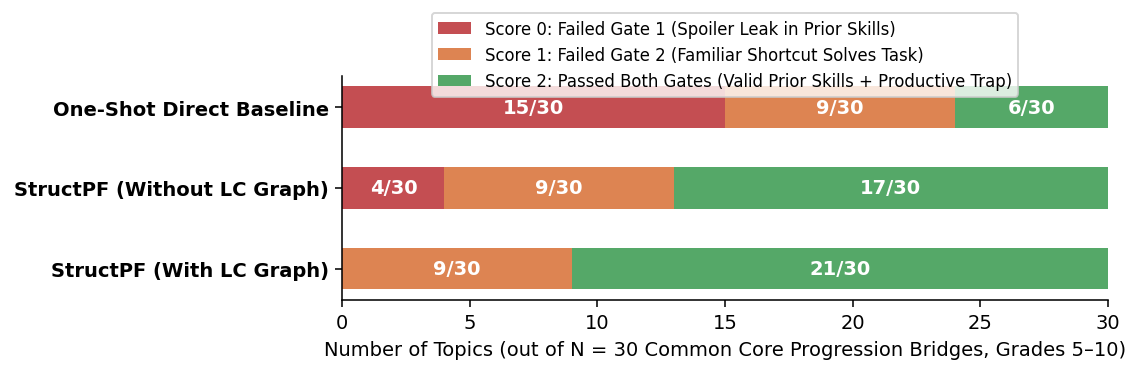

In [7]:
# Plot the 30-topic 3-arm Two-Gate distribution directly from the saved benchmark summary
summary_3 = json.loads((pb_dir / "summary_three_arm.json").read_text(encoding="utf-8"))
arms_summary = summary_3["summary"]["arms"]

arm_order = [
    ("direct", "One-Shot Direct Baseline"),
    ("ungrounded", "StructPF (Without LC Graph)"),
    ("lc_grounded", "StructPF (With LC Graph)"),
]

s0 = [arms_summary[k]["score_counts"]["score_0_invalid_prior_set"] for k, _ in arm_order]
s1 = [arms_summary[k]["score_counts"]["score_1_trap_bypassed_or_off_target"] for k, _ in arm_order]
s2 = [arms_summary[k]["score_counts"]["score_2_productive_trap"] for k, _ in arm_order]
labels = [lbl for _, lbl in arm_order]

fig, ax = plt.subplots(figsize=(8.2, 3.0), dpi=140)
y = range(len(arm_order))
ax.barh(y, s0, height=0.52, color="#C44E52", label="Score 0: Failed Gate 1 (Spoiler Leak in Prior Skills)")
ax.barh(y, s1, left=s0, height=0.52, color="#DD8452", label="Score 1: Failed Gate 2 (Familiar Shortcut Solves Task)")
ax.barh(
    y,
    s2,
    left=[a + b for a, b in zip(s0, s1)],
    height=0.52,
    color="#55A868",
    label="Score 2: Passed Both Gates (Valid Prior Skills + Productive Trap)",
)

for idx in range(len(arm_order)):
    if s0[idx] >= 2:
        ax.text(s0[idx] / 2, idx, f"{s0[idx]}/30", ha="center", va="center", color="white", fontweight="bold")
    if s1[idx] >= 3:
        ax.text(s0[idx] + s1[idx] / 2, idx, f"{s1[idx]}/30", ha="center", va="center", color="white", fontweight="bold")
    if s2[idx] >= 3:
        ax.text(
            s0[idx] + s1[idx] + s2[idx] / 2,
            idx,
            f"{s2[idx]}/30",
            ha="center",
            va="center",
            color="white",
            fontweight="bold",
        )

ax.set_yticks(list(y))
ax.set_yticklabels(labels, fontweight="bold")
ax.set_xlabel("Number of Topics (out of N = 30 Common Core Progression Bridges, Grades 5–10)")
ax.set_xlim(0, 30)
ax.invert_yaxis()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.32), ncol=1, frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

### Live Step 2b Calculator Repair Demo: Turning a Shortcut-Solvable Draft into a Verified PF Trap

Finally, suppose a teacher (or an initial Step 2b proposal) writes a Grade 8 linear-function problem comparing workshop plans from two data points $(x_1, y_1)$ and $(x_2, y_2)$:
- **Draft Proposal 1 (Flawed):** Plan A has points $(2, 6)$ and $(6, 18)$ (passes through $(0, 0)$ with zero initial fee, so the Grade 7 proportional ratio $y / x = 3$ is constant and solves the rate of change without needing $\Delta y / \Delta x$).
- **Repaired Proposal 2 (Verified PF Trap):** Plan A has points $(2, 9)$ and $(6, 17)$ (initial fee $b = 5 > 0$, rate $m = 2$). Now the familiar Grade 7 unit-rate check $y / x$ gives $9 / 2 = 4.5$ at $x = 2$ and $17 / 6 \approx 2.83$ at $x = 6$ ($9/2 \neq 17/6$, breaking the proportional shortcut), while the true rate of change $\Delta y / \Delta x = (17 - 9) / (6 - 2) = 2$ is well defined.

Below, we run `calculate_condition` from `src/generation/design_calculator.py` live on both number sets:

In [8]:
# Condition: The familiar Grade 7 unit-rate shortcut y1/x1 == y2/x2 must NOT hold (so the proportional shortcut fails)
shortcut_breaks_calc = {
    "expressions": {
        "naive_ratio_1": "y1 / x1",
        "naive_ratio_2": "y2 / x2",
        "true_slope": "(y2 - y1) / (x2 - x1)",
        "initial_fee": "y1 - true_slope * x1",
    },
    "predicate": "naive_ratio_1 != naive_ratio_2 and true_slope > 0 and initial_fee > 0",
    "symbols": {},
}

draft_flawed_values = {"x1": 2, "y1": 6, "x2": 6, "y2": 18}
repaired_pf_values = {"x1": 2, "y1": 9, "x2": 6, "y2": 17}

res_flawed = calculate_condition(shortcut_breaks_calc, draft_flawed_values)
res_repaired = calculate_condition(shortcut_breaks_calc, repaired_pf_values)

repair_df = pd.DataFrame(
    [
        {
            "Proposal": "Draft Proposal 1 (Proportional: (2, 6) & (6, 18))",
            "Naive Ratio y1/x1": res_flawed["computed"]["naive_ratio_1"],
            "Naive Ratio y2/x2": res_flawed["computed"]["naive_ratio_2"],
            "True Rate (y2-y1)/(x2-x1)": res_flawed["computed"]["true_slope"],
            "Initial Fee b": res_flawed["computed"]["initial_fee"],
            "Step 2b Calculator Verdict": "REJECTED (Shortcut works: y1/x1 == y2/x2)"
            if res_flawed["status"] != "holds"
            else "ACCEPTED",
        },
        {
            "Proposal": "Repaired Proposal 2 (Non-Zero Intercept: (2, 9) & (6, 17))",
            "Naive Ratio y1/x1": res_repaired["computed"]["naive_ratio_1"],
            "Naive Ratio y2/x2": res_repaired["computed"]["naive_ratio_2"],
            "True Rate (y2-y1)/(x2-x1)": res_repaired["computed"]["true_slope"],
            "Initial Fee b": res_repaired["computed"]["initial_fee"],
            "Step 2b Calculator Verdict": "ACCEPTED (Shortcut fails: 9/2 != 17/6; Δy/Δx = 2)"
            if res_repaired["status"] == "holds"
            else "REJECTED",
        },
    ]
)
display(repair_df)

,Proposal,Naive Ratio y1/x1,Naive Ratio y2/x2,True Rate (y2-y1)/(x2-x1),Initial Fee b,Step 2b Calculator Verdict
0,"Draft Proposal 1 (Proportional: (2, 6) & (6, 18))",3,3,3,0,REJECTED (Shortcut works: y1/x1 == y2/x2)
1,"Repaired Proposal 2 (Non-Zero Intercept: (2, 9) & (6, 17))",9/2,17/6,2,5,ACCEPTED (Shortcut fails: 9/2 != 17/6; Δy/Δx = 2)
